# 7. Ajuste del umbral de decisión

El modelo no dice "sobrevive / no sobrevive": da una **probabilidad**. Por defecto se usa el corte **0.5**:

- probabilidad ≥ 0.5 → *sobrevive*
- probabilidad < 0.5 → *no sobrevive*

Pero 0.5 es arbitrario. En el cuaderno 5, con 0.5 el modelo tuvo **sensibilidad 0.68** (solo detecta 68 % de los que sí sobrevivieron) y **especificidad 0.88**. Mover el umbral cambia ese equilibrio:

| Umbral | Efecto |
|---|---|
| Más bajo (ej. 0.35) | Más pasajeros clasificados como "sobrevive" → ↑ sensibilidad, ↓ especificidad |
| Más alto (ej. 0.65) | Menos pasajeros clasificados como "sobrevive" → ↓ sensibilidad, ↑ especificidad |

**Regla de oro:** el umbral se elige **solo con datos de entrenamiento** (predicciones *fuera de pliegue* con validación cruzada). El conjunto de prueba se usa **una sola vez al final** para verificar. Si eligiéramos el umbral viendo la prueba, el resultado sería optimista y tramposo.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, ConfusionMatrixDisplay)

import titanic_features  # necesario para cargar el pipeline

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42

## 7.1 Modelo y datos
Usamos el **pipeline final del cuaderno 5** (Gradient Boosting ya ajustado), que parte de los datos originales y no tiene fuga de información. Se usa la misma partición 80/20.

In [2]:
raw = pd.read_csv("data/titanic.csv")
X = raw.drop(columns="Survived")
y = raw["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

pipeline = clone(joblib.load("models/titanic_pipeline.joblib"))   # mismos hiperparámetros, sin entrenar
print(pipeline.named_steps["model"])

GradientBoostingClassifier(learning_rate=0.03, max_depth=4, n_estimators=200,
                           random_state=42)


## 7.2 Probabilidades fuera de pliegue (solo entrenamiento)
Con `cross_val_predict` cada pasajero de entrenamiento recibe una probabilidad calculada por un modelo que **no lo vio** al entrenar. Así simulamos datos nuevos sin tocar la prueba.

AUC fuera de pliegue: 0.8914


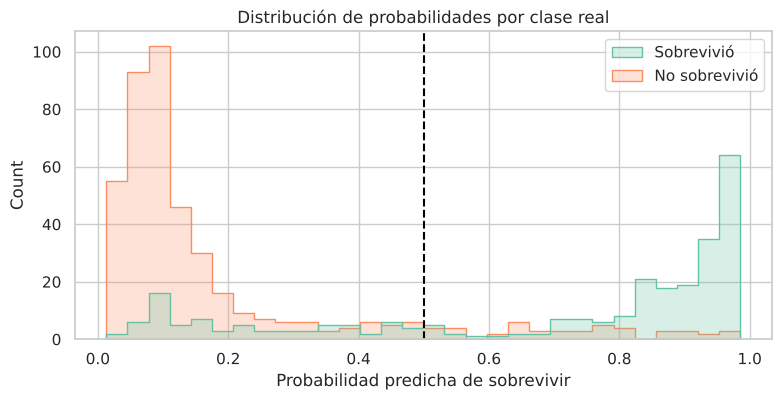

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
proba_oof = cross_val_predict(pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
print("AUC fuera de pliegue:", round(roc_auc_score(y_train, proba_oof), 4))

plt.figure(figsize=(9, 4))
sns.histplot(x=proba_oof, hue=y_train.map({0: "No sobrevivió", 1: "Sobrevivió"}).values, bins=30, element="step", stat="count")
plt.axvline(0.5, color="k", ls="--", label="Umbral 0.5")
plt.xlabel("Probabilidad predicha de sobrevivir"); plt.title("Distribución de probabilidades por clase real")
plt.show()

La zona donde las dos distribuciones se **traslapan** es donde el modelo duda. El umbral decide de qué lado cae esa zona.

## 7.3 Métricas para cada umbral posible

In [4]:
def metricas(y_real, proba, u):
    pred = (proba >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else 0
    esp = tn / (tn + fp) if tn + fp else 0
    prec = tp / (tp + fp) if tp + fp else 0
    f1 = 2 * prec * sens / (prec + sens) if prec + sens else 0
    return {"umbral": u, "exactitud": (tp + tn) / len(y_real), "precision": prec,
            "sensibilidad": sens, "especificidad": esp, "f1": f1,
            "exactitud_balanceada": (sens + esp) / 2, "youden_J": sens + esp - 1,
            "TP": tp, "FP": fp, "TN": tn, "FN": fn}

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
curva = pd.DataFrame([metricas(y_train, proba_oof, u) for u in umbrales]).set_index("umbral")
curva.loc[[0.3, 0.4, 0.5, 0.6, 0.7], ["exactitud", "precision", "sensibilidad", "especificidad", "f1"]].round(3)

,exactitud,precision,sensibilidad,especificidad,f1
umbral,,,,,
0.3,0.823,0.746,0.817,0.827,0.780
0.4,0.826,0.773,0.773,0.859,0.773
0.5,0.831,0.815,0.725,0.897,0.767
0.6,0.831,0.837,0.696,0.916,0.760
0.7,0.836,0.875,0.667,0.941,0.757


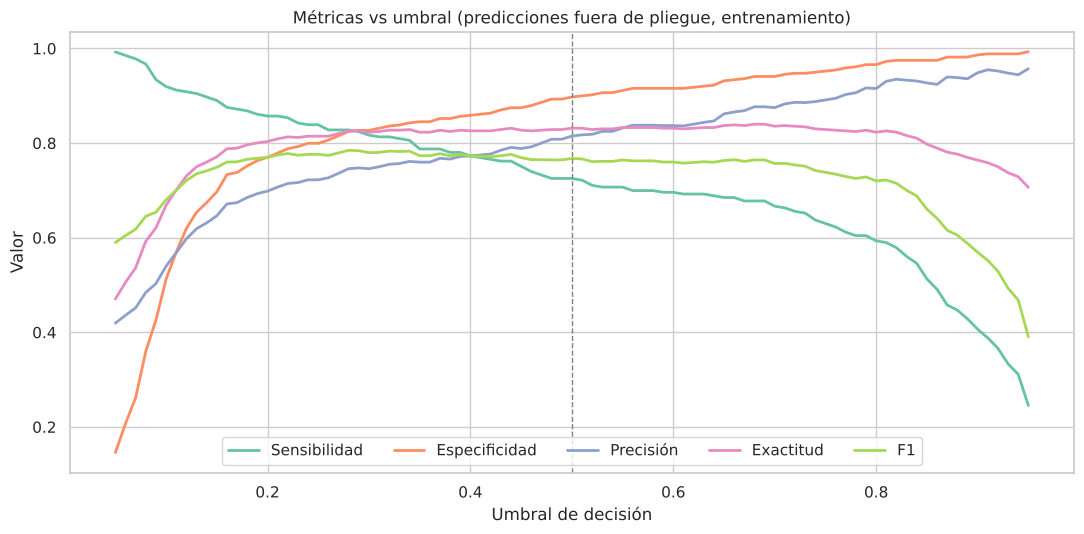

In [5]:
fig, ax = plt.subplots(figsize=(11, 5.5))
for col, lab in [("sensibilidad", "Sensibilidad"), ("especificidad", "Especificidad"),
                 ("precision", "Precisión"), ("exactitud", "Exactitud"), ("f1", "F1")]:
    ax.plot(curva.index, curva[col], label=lab, lw=2)
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Valor")
ax.set_title("Métricas vs umbral (predicciones fuera de pliegue, entrenamiento)")
ax.legend(loc="lower center", ncol=5)
plt.tight_layout(); plt.show()

**Lectura de la gráfica:** la sensibilidad baja y la especificidad sube conforme el umbral aumenta. **No existe un umbral que maximice todo**: hay que elegir con un criterio.

## 7.4 Criterios para elegir el umbral

| Criterio | Qué busca | Cuándo usarlo |
|---|---|---|
| **0.5 (por defecto)** | Nada en especial | Referencia |
| **Índice de Youden** (máx. sensibilidad + especificidad − 1) | El mejor equilibrio entre ambas | Cuando los dos errores importan igual |
| **Máximo F1** | Equilibrio entre precisión y sensibilidad | Cuando importa sobre todo la clase positiva |
| **Máxima exactitud** | El mayor % de aciertos | Cuando solo importa acertar más en total |
| **Sensibilidad ≥ 0.80** | Detectar al menos 80 % de sobrevivientes | Cuando omitir un positivo es caro (ej. rescate, diagnóstico médico) |

In [6]:
criterios = {
    "Por defecto (0.5)": 0.50,
    "Youden (equilibrio)": curva["youden_J"].idxmax(),
    "Máximo F1": curva["f1"].idxmax(),
    "Máxima exactitud": curva["exactitud"].idxmax(),
    "Sensibilidad ≥ 0.80": curva[curva["sensibilidad"] >= 0.80].index.max(),
}
tabla_train = pd.DataFrame({k: curva.loc[u] for k, u in criterios.items()}).T
tabla_train.insert(0, "umbral", list(criterios.values()))
tabla_train[["umbral", "exactitud", "precision", "sensibilidad", "especificidad", "f1"]].astype(float).round(3)

,umbral,exactitud,precision,sensibilidad,especificidad,f1
Por defecto (0.5),0.50,0.831,0.815,0.725,0.897,0.767
Youden (equilibrio),0.28,0.826,0.746,0.828,0.825,0.785
Máximo F1,0.28,0.826,0.746,0.828,0.825,0.785
Máxima exactitud,0.68,0.840,0.877,0.678,0.941,0.764
Sensibilidad ≥ 0.80,0.34,0.829,0.761,0.806,0.843,0.783


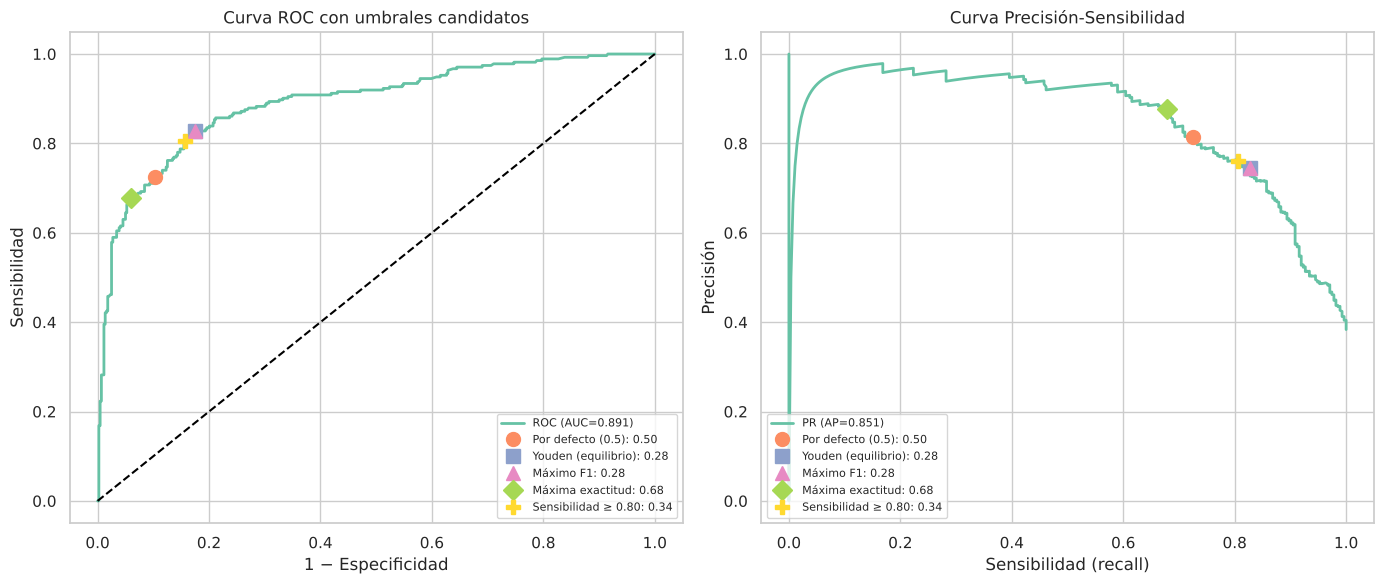

In [7]:
fpr, tpr, thr = roc_curve(y_train, proba_oof)
prec_c, rec_c, thr_pr = precision_recall_curve(y_train, proba_oof)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].plot(fpr, tpr, lw=2, label=f"ROC (AUC={roc_auc_score(y_train, proba_oof):.3f})")
axes[0].plot([0, 1], [0, 1], "k--")
axes[1].plot(rec_c, prec_c, lw=2, label=f"PR (AP={average_precision_score(y_train, proba_oof):.3f})")
marcas = ["o", "s", "^", "D", "P"]
for (nombre, u), mk in zip(criterios.items(), marcas):
    r = curva.loc[u]
    axes[0].plot(1 - r["especificidad"], r["sensibilidad"], mk, ms=10, label=f"{nombre}: {u:.2f}")
    axes[1].plot(r["sensibilidad"], r["precision"], mk, ms=10, label=f"{nombre}: {u:.2f}")
axes[0].set_xlabel("1 − Especificidad"); axes[0].set_ylabel("Sensibilidad"); axes[0].set_title("Curva ROC con umbrales candidatos")
axes[1].set_xlabel("Sensibilidad (recall)"); axes[1].set_ylabel("Precisión"); axes[1].set_title("Curva Precisión-Sensibilidad")
for a in axes: a.legend(fontsize=8, loc="lower left" if a is axes[1] else "lower right")
plt.tight_layout(); plt.show()

## 7.5 ¿Qué tan estable es el umbral elegido?
Repetimos las predicciones fuera de pliegue con **10 mezclas distintas** y vemos dónde cae el umbral de Youden cada vez. Si salta mucho, no conviene confiar en un valor exacto.

In [8]:
youden_rep, f1_rep = [], []
for s in range(10):
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=s)
    p = cross_val_predict(pipeline, X_train, y_train, cv=cv_s, method="predict_proba", n_jobs=-1)[:, 1]
    c = pd.DataFrame([metricas(y_train, p, u) for u in umbrales]).set_index("umbral")
    youden_rep.append(c["youden_J"].idxmax())
    f1_rep.append(c["f1"].idxmax())

estab = pd.DataFrame({"Youden": youden_rep, "F1": f1_rep})
print(estab.describe().loc[["mean", "std", "min", "max"]].round(3))

      Youden     F1
mean   0.354  0.384
std    0.107  0.124
min    0.250  0.250
max    0.590  0.590


In [9]:
umbral_elegido = float(np.round(np.median(youden_rep), 2))
print("Umbral elegido (mediana del umbral de Youden en 10 repeticiones):", umbral_elegido)

Umbral elegido (mediana del umbral de Youden en 10 repeticiones): 0.32


Se usa la **mediana** de las 10 repeticiones en lugar de un solo valor para que el umbral no dependa de una mezcla en particular.

## 7.6 Verificación final en el conjunto de prueba (una sola vez)

In [10]:
modelo = clone(pipeline).fit(X_train, y_train)
proba_test = modelo.predict_proba(X_test)[:, 1]

comparar = {"Por defecto (0.5)": 0.5,
            f"Elegido ({umbral_elegido:.2f})": umbral_elegido,
            "Sensibilidad ≥ 0.80": criterios["Sensibilidad ≥ 0.80"]}
tabla_test = pd.DataFrame({k: metricas(y_test, proba_test, u) for k, u in comparar.items()}).T
tabla_test = tabla_test[["umbral", "exactitud", "precision", "sensibilidad", "especificidad", "f1", "TP", "FN", "TN", "FP"]]
tabla_test.to_csv("results/umbral_prueba.csv")
tabla_test.astype(float).round(3)

,umbral,exactitud,precision,sensibilidad,especificidad,f1,TP,FN,TN,FP
Por defecto (0.5),0.50,0.804,0.783,0.681,0.882,0.729,47.0,22.0,97.0,13.0
Elegido (0.32),0.32,0.793,0.705,0.797,0.791,0.748,55.0,14.0,87.0,23.0
Sensibilidad ≥ 0.80,0.34,0.804,0.724,0.797,0.809,0.759,55.0,14.0,89.0,21.0


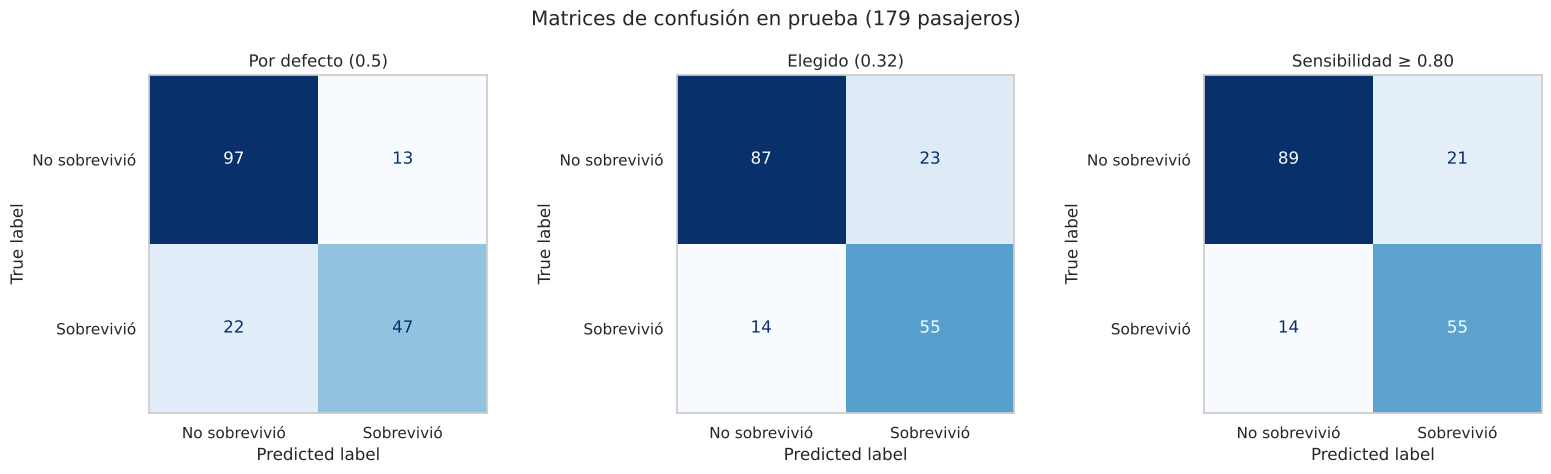

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nombre, u) in zip(axes, comparar.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= u).astype(int), ax=ax, cmap="Blues",
                                            display_labels=["No sobrevivió", "Sobrevivió"], colorbar=False)
    ax.set_title(nombre); ax.grid(False)
plt.suptitle("Matrices de confusión en prueba (179 pasajeros)")
plt.tight_layout(); plt.show()

In [12]:
with open("results/umbral.txt", "w") as f:
    f.write(str(umbral_elegido))
print("Guardado results/umbral.txt ->", umbral_elegido, "(lo usa app.py)")

Guardado results/umbral.txt -> 0.32 (lo usa app.py)


## 7.7 Conclusiones

**1. El umbral 0.5 favorece la especificidad.** Con 0.5 el modelo casi no se equivoca con los que no sobrevivieron (especificidad 0.88 en prueba), pero se le escapa **1 de cada 3 sobrevivientes** (sensibilidad 0.68: 22 de 69).

**2. Umbral elegido: 0.32** (mediana del índice de Youden en 10 repeticiones, calculado solo con entrenamiento). En el conjunto de prueba:

| | Umbral 0.5 | Umbral 0.32 | Cambio |
|---|---|---|---|
| Sensibilidad | 0.681 | **0.797** | **+0.116** |
| Especificidad | 0.882 | 0.791 | −0.091 |
| Precisión | 0.783 | 0.705 | −0.078 |
| Exactitud | 0.804 | 0.793 | −0.011 |
| F1 | 0.729 | **0.748** | +0.019 |
| Sobrevivientes detectados (TP) | 47 de 69 | **55 de 69** | **+8** |
| Falsas alarmas (FP) | 13 | 23 | +10 |

Se detectan **8 sobrevivientes más** a cambio de **10 falsas alarmas más**. La exactitud casi no cambia (−1.1 puntos), pero el modelo queda **más equilibrado**: sensibilidad y especificidad pasan de una brecha de 20 puntos a quedar prácticamente iguales (~0.80 / ~0.79).

**3. El resultado de entrenamiento se confirmó en prueba.** Con predicciones fuera de pliegue se esperaba una sensibilidad cercana a 0.80 con umbral bajo, y en prueba salió 0.797. Esto indica que el umbral **generaliza** y no se "sobreajustó".

**4. El umbral óptimo exacto es inestable** (Youden varió entre 0.25 y 0.59 según la mezcla de datos, desviación 0.11). La curva de Youden es **plana** entre ~0.28 y ~0.40: cualquier valor en ese rango da resultados parecidos. Por eso se reporta la mediana y no un valor "mágico".

**5. La elección depende del uso.** Si el objetivo fuera, por ejemplo, **priorizar rescates** (no dejar a nadie que pudiera sobrevivir sin atender), conviene el umbral bajo. Si las falsas alarmas fueran caras, conviene 0.5 o más. **La AUC (0.85–0.89) no cambia con el umbral**: el umbral no hace al modelo más inteligente, solo decide **qué tipo de error preferimos cometer**.

**Aplicación:** `app.py` ahora usa el umbral guardado en `results/umbral.txt` (0.32).

**Siguiente paso:** interpretación con SHAP.